# LeetCode #138: Copy List with Random Pointer

https://leetcode.com/problems/copy-list-with-random-pointer/

## Comparison of Approaches
| Approach | Time | Space |
|---|---|---|
| HashMap | O(n) | O(n) |
| Interleaving Nodes ★ | O(n) | O(1) |

## Understanding the Methods
### Brute Force (HashMap)
First pass: create a clone of each node and store in a hashmap (original → clone). Second pass: set next and random pointers using the hashmap. O(n) time and space.

### Optimal: Interleaving Nodes ★
Three passes without extra space:
1. Insert a clone after each original node (A→A'→B→B'...)
2. Set random pointers: clone.random = original.random.next
3. Separate the two lists. O(n) time, O(1) extra space.

## Solutions
### C#

In [ ]:
// HashMap O(n) time, O(n) space
public class Node {
    public int val;
    public Node next;
    public Node random;
    public Node(int _val) { val = _val; }
}

public class Solution {
    public Node CopyRandomList(Node head) {
        if (head == null) return null;
        var map = new Dictionary<Node, Node>();
        var cur = head;
        while (cur != null) { map[cur] = new Node(cur.val); cur = cur.next; }
        cur = head;
        while (cur != null) {
            if (cur.next != null) map[cur].next = map[cur.next];
            if (cur.random != null) map[cur].random = map[cur.random];
            cur = cur.next;
        }
        return map[head];
    }
}

### Python

In [ ]:
# HashMap O(n) time, O(n) space
class Node:
    def __init__(self, x, next=None, random=None):
        self.val = x
        self.next = next
        self.random = random

class Solution:
    def copyRandomList(self, head: 'Optional[Node]') -> 'Optional[Node]':
        if not head: return None
        node_map = {}
        cur = head
        while cur:
            node_map[cur] = Node(cur.val)
            cur = cur.next
        cur = head
        while cur:
            if cur.next: node_map[cur].next = node_map[cur.next]
            if cur.random: node_map[cur].random = node_map[cur.random]
            cur = cur.next
        return node_map[head]

### Go

In [ ]:
// HashMap O(n) time, O(n) space
type Node struct {
    Val int
    Next *Node
    Random *Node
}

func copyRandomList(head *Node) *Node {
    if head == nil { return nil }
    nodeMap := make(map[*Node]*Node)
    for cur := head; cur != nil; cur = cur.Next {
        nodeMap[cur] = &Node{Val: cur.Val}
    }
    for cur := head; cur != nil; cur = cur.Next {
        if cur.Next != nil { nodeMap[cur].Next = nodeMap[cur.Next] }
        if cur.Random != nil { nodeMap[cur].Random = nodeMap[cur.Random] }
    }
    return nodeMap[head]
}

### Rust

In [ ]:
// HashMap approach O(n) time, O(n) space
// Note: Rust's ownership model makes linked list cloning non-trivial;
// typically solved with Rc<RefCell<Node>> or unsafe pointers.
use std::collections::HashMap;

pub struct Node { pub val: i32, pub next: Option<Box<Node>>, pub random: *mut Node }

impl Node {
    pub fn new(val: i32) -> Self {
        Node { val, next: None, random: std::ptr::null_mut() }
    }
}

## Example Scenarios

### 1. Common Case — random pointers across the list
**Input:** head = [[7,null],[13,0],[11,4],[10,2],[1,0]]
Each pair is $[val, randomIndex]$. We clone every node and then wire each clone's `random` to the clone of the original's random target (e.g. node 13's random &rarr; node 0). Returns a fully independent deep copy.

### 2. Slightly Complex — randoms point within the list
**Input:** head = [[1,1],[2,1]]
Both nodes' random pointers target index 1. The clone must reproduce that shared target using cloned nodes, never the originals. Deep copy preserved.

### 3. Edge Case: Time Factor — single node, no random
**Input:** head = [[3,null]]
One node whose random is null. A single clone is created; the null random copies straight across. Minimal $O(1)$ work.

### 4. Edge Case: Space Factor — self-referential random
**Input:** head = [[1,0]]
A single node whose random points to itself (index 0). The clone's random must point to the clone, not the original — the classic self-loop trap. Deep copy preserved.

### 5. Almost-Impossible but Plausible — empty list
**Input:** head = []
No nodes to copy; the function short-circuits and returns **null**.


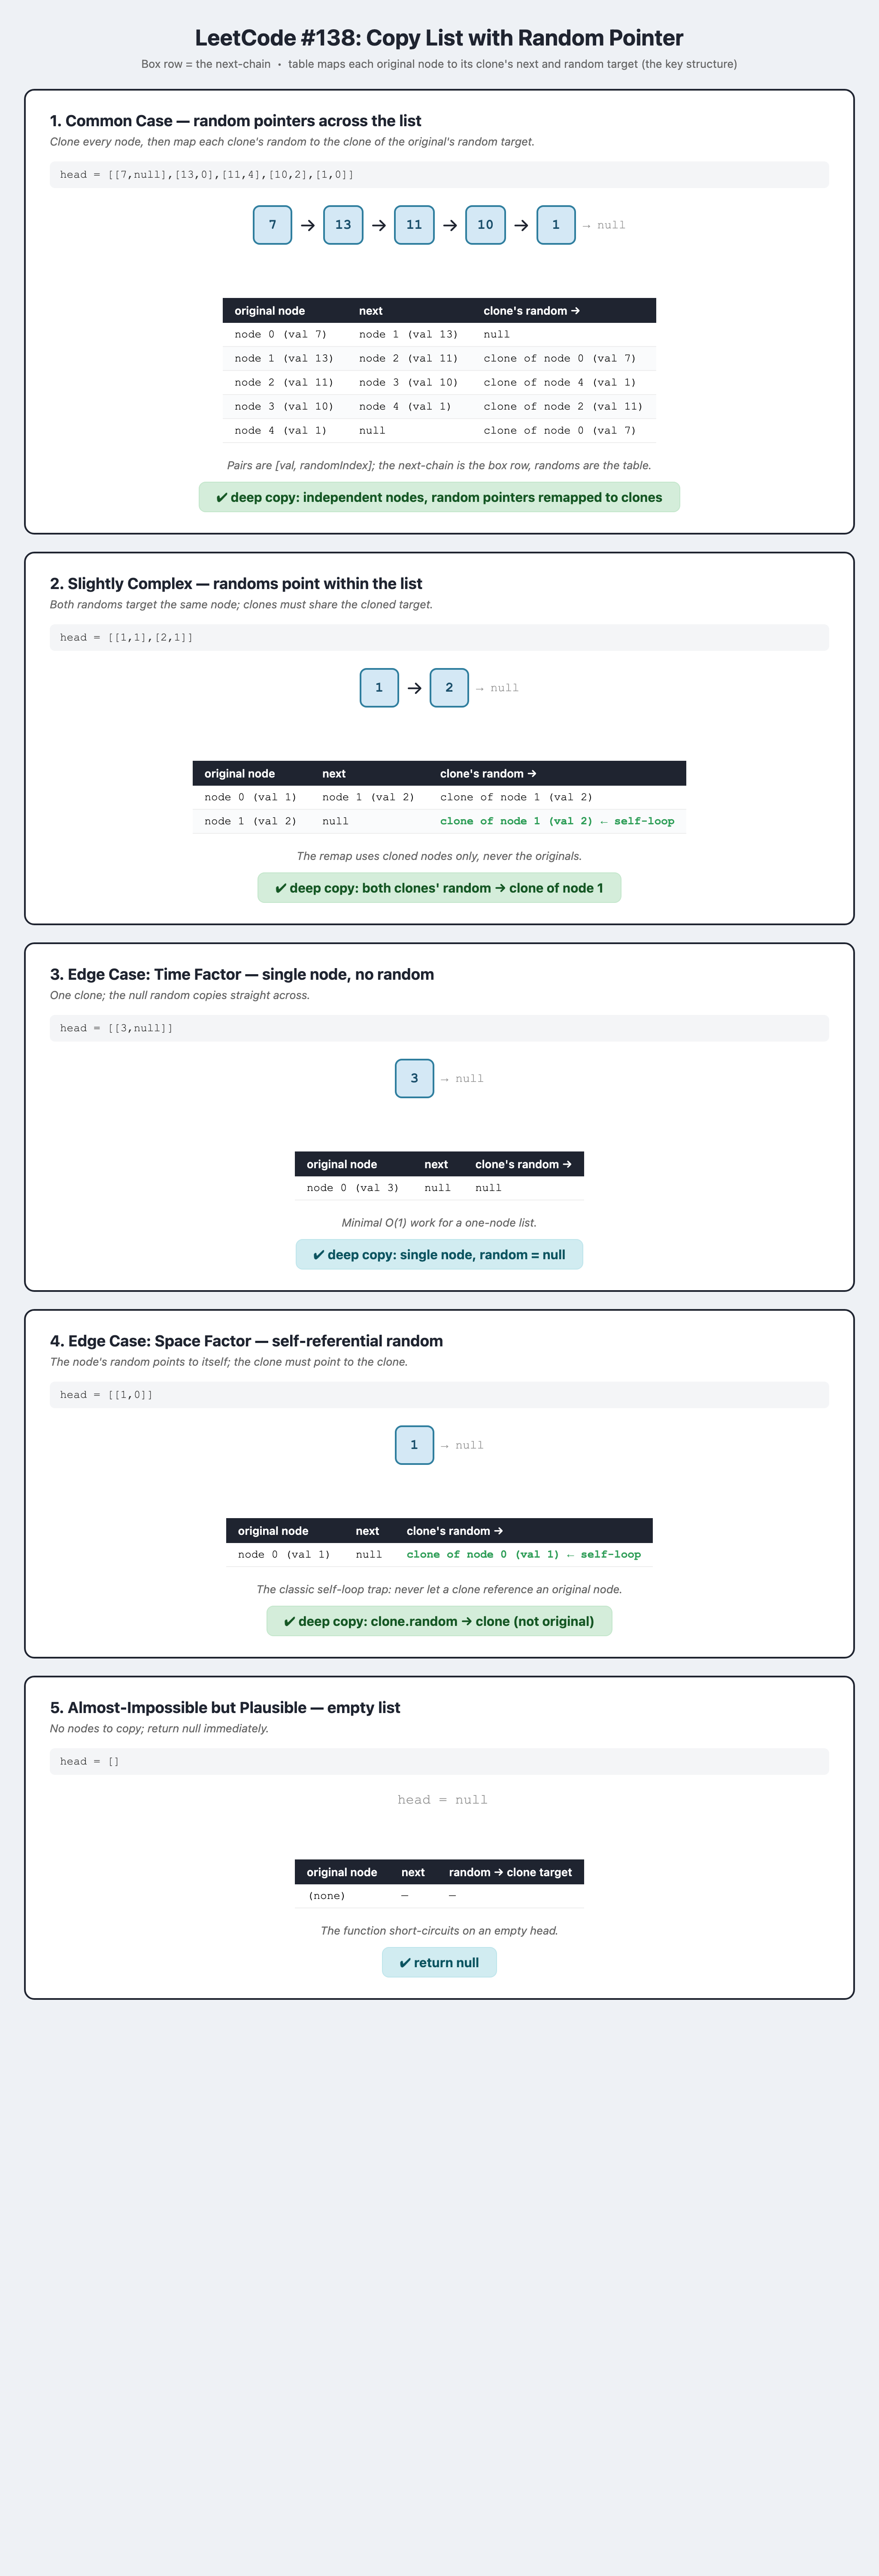